# Phase 1

**AI and Visualization Lab**

We use the **same trained CNN** and the **Fashion-MNIST test set** as the other pair. We do **not** train a new model here.

Our plan is simple:
1. Check what the model gets wrong.
2. Look at shirt images that it mistakes for coats.
3. Check whether brighter pixels near the sides of shirts are linked to this mistake.
4. Look at how confident the model is.

**Our different approach:** Instead of counting how many side pixels pass a brightness threshold, we just calculate the **average brightness** of the two side areas. This is easy to explain and tests the same idea in another way.

## 1. Load the images and the trained model

Fashion-MNIST has 10 clothing categories. We only need the **10,000 test images**.

Keep `fashion_cnn.pth` in the same folder as this notebook. If you use Google Colab, upload that file first.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

test_data = datasets.FashionMNIST("data", train=False, download=True,
                                  transform=transforms.ToTensor())

names = test_data.classes
print("Test images:", len(test_data))
print("Classes:", names)

100%|██████████| 26.4M/26.4M [00:02<00:00, 9.30MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 139kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.59MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 28.2MB/s]

Test images: 10000
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [ ]:
model = nn.Sequential(
    nn.Conv2d(1, 16, 3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(32 * 7 * 7, 64),
    nn.ReLU(),
    nn.Linear(64, 10)
)

model.load_state_dict(torch.load("fashion_cnn.pth", map_location="cpu", weights_only=True))
model.eval()
print("Model loaded!")

Model loaded!


## 2. Check all the test images

For every image, we save three things: the **correct label**, the model's **prediction**, and its **probabilities** for the 10 classes.

In [4]:
loader = DataLoader(test_data, batch_size=128, shuffle=False)
actual = []
predicted = []
probabilities = []

with torch.no_grad():
    for images, labels in loader:
        scores = model(images)
        probs = torch.softmax(scores, dim=1)

        actual.extend(labels.tolist())
        predicted.extend(probs.argmax(dim=1).tolist())
        probabilities.extend(probs.tolist())

actual = np.array(actual)
predicted = np.array(predicted)
probabilities = np.array(probabilities)

print("Images checked:", len(predicted))
print(f"Overall accuracy: {(actual == predicted).mean():.1%}")

Images checked: 10000
Overall accuracy: 87.3%


## 3. Model's mistakes?

A **confusion matrix** shows what the correct clothes were and what the model guessed.

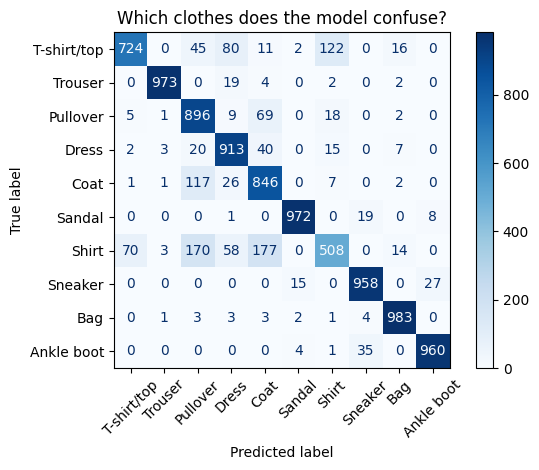

Most common mistake: Shirt -> Coat
Number of times: 177


In [5]:
matrix = confusion_matrix(actual, predicted)

ConfusionMatrixDisplay(matrix, display_labels=names).plot(
    cmap="Blues", xticks_rotation=45, values_format="d"
)
plt.title("Which clothes does the model confuse?")
plt.tight_layout()
plt.show()

errors_only = matrix.copy()
np.fill_diagonal(errors_only, 0)
true_class, guessed_class = np.unravel_index(errors_only.argmax(), errors_only.shape)

print("Most common mistake:", names[true_class], "->", names[guessed_class])
print("Number of times:", errors_only[true_class, guessed_class])

We focus on **Shirt → Coat**, because that is the main error we want to investigate.

Let's compare a few real shirts the model recognized correctly with a few it called coats.

Shirts correctly called Shirt: 508
Shirts incorrectly called Coat: 177


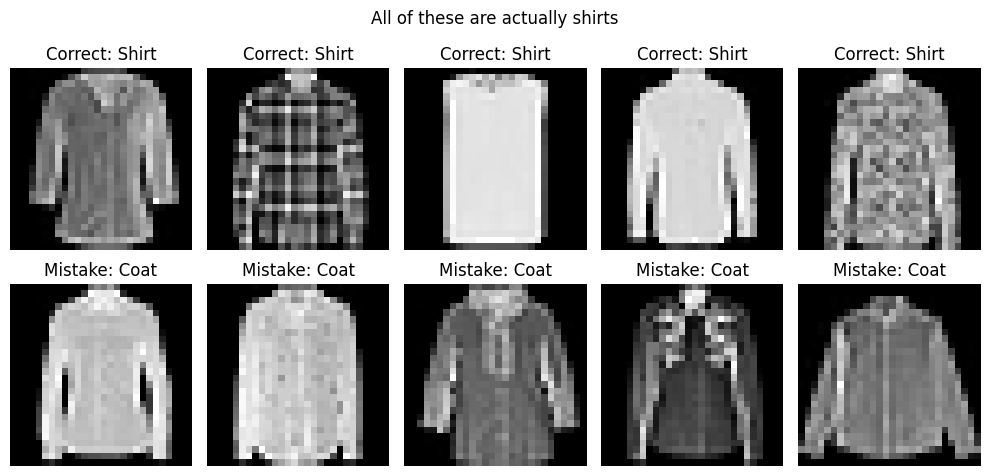

In [6]:
shirt = names.index("Shirt")
coat = names.index("Coat")

correct = np.where((actual == shirt) & (predicted == shirt))[0]
wrong = np.where((actual == shirt) & (predicted == coat))[0]

print("Shirts correctly called Shirt:", len(correct))
print("Shirts incorrectly called Coat:", len(wrong))

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for row, examples, title in [(0, correct, "Correct: Shirt"),
                             (1, wrong, "Mistake: Coat")]:
    for ax, number in zip(axes[row], examples[:5]):
        image, _ = test_data[int(number)]
        ax.imshow(image[0], cmap="gray")
        ax.set_title(title)
        ax.axis("off")

plt.suptitle("All of these are actually shirts")
plt.tight_layout()
plt.show()

## 4. Our question: do brighter sides cause more confusion?

**Our idea:** Some shirts have more visible material around the lower sides. Maybe the model then thinks they look more likely to be coats.

We measure something simple: the **average pixel brightness** on the left and right sides of each shirt. Higher values mean brighter pixels in those areas.

This is **not** a real measurement of sleeve length. Body width, colors and other image details also affect brightness. We are checking for a pattern, not proving the reason for the mistake.

In [7]:
shirt_images = np.where(actual == shirt)[0]
side_brightness = []

for number in shirt_images:
    image, _ = test_data[int(number)]
    pixels = image[0].numpy()

    left_side = pixels[15:24, 2:8]
    right_side = pixels[15:24, 20:26]

    brightness = (left_side.mean() + right_side.mean()) / 2
    side_brightness.append(brightness)

side_brightness = np.array(side_brightness)

# Split shirts into two roughly equal groups.
midpoint = np.median(side_brightness)
low = side_brightness <= midpoint
high = side_brightness > midpoint

print("Shirts with less bright sides:", low.sum())
print("Shirts with brighter sides:", high.sum())

Shirts with less bright sides: 500
Shirts with brighter sides: 500


Now we ask: **In each group, what percentage of the shirts were called coats?**

Using percentages is important because the two groups may have slightly different sizes.

Less bright sides: 6.4% mistaken for coats
Brighter sides: 29.0% mistaken for coats


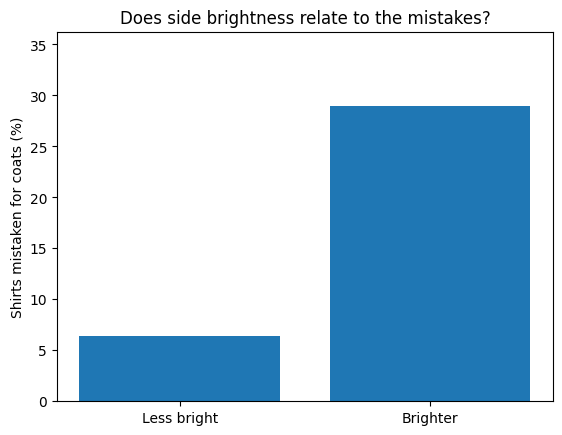

In [8]:
shirt_predictions = predicted[shirt_images]

low_rate = 100 * (shirt_predictions[low] == coat).mean()
high_rate = 100 * (shirt_predictions[high] == coat).mean()

print(f"Less bright sides: {low_rate:.1f}% mistaken for coats")
print(f"Brighter sides: {high_rate:.1f}% mistaken for coats")

plt.bar(["Less bright", "Brighter"], [low_rate, high_rate])
plt.ylabel("Shirts mistaken for coats (%)")
plt.title("Does side brightness relate to the mistakes?")
plt.ylim(0, max(low_rate, high_rate, 1) * 1.25)
plt.show()

We can also check the other side of the story: **what percentage were correctly recognized as shirts?**

In [9]:
low_correct = 100 * (shirt_predictions[low] == shirt).mean()
high_correct = 100 * (shirt_predictions[high] == shirt).mean()

print(f"Less bright sides: {low_correct:.1f}% correctly called Shirt")
print(f"Brighter sides: {high_correct:.1f}% correctly called Shirt")

Less bright sides: 60.6% correctly called Shirt
Brighter sides: 41.0% correctly called Shirt


## 5. How confident is the model when it makes the Shirt → Coat mistake?

The model doesn't just say "Coat". It gives a number between 0 and 1 for each class.
For example, **0.80** means **80% softmax probability** assigned to that class.
This is the model's score, not a guarantee that it is right.

Average P(Coat) on mistakes: 66.4%
Average P(Shirt) on mistakes: 17.4%


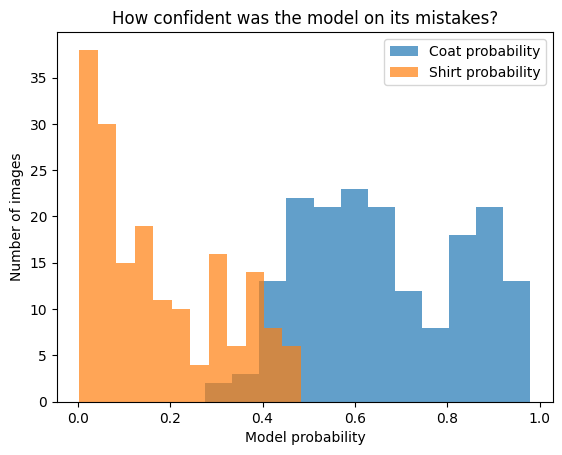

In [10]:
coat_on_mistakes = probabilities[wrong, coat]
shirt_on_mistakes = probabilities[wrong, shirt]

print(f"Average P(Coat) on mistakes: {coat_on_mistakes.mean():.1%}")
print(f"Average P(Shirt) on mistakes: {shirt_on_mistakes.mean():.1%}")

plt.hist(coat_on_mistakes, bins=12, alpha=0.7, label="Coat probability")
plt.hist(shirt_on_mistakes, bins=12, alpha=0.7, label="Shirt probability")
plt.xlabel("Model probability")
plt.ylabel("Number of images")
plt.title("How confident was the model on its mistakes?")
plt.legend()
plt.show()

## 6. Does side brightness also change the model's Coat probability?

We already compared **mistake rates**. Now we compare the *average Coat probability* for **all shirts**, including those that were classified correctly.

Less bright sides: average P(Coat) = 8.8%
Brighter sides: average P(Coat) = 29.5%


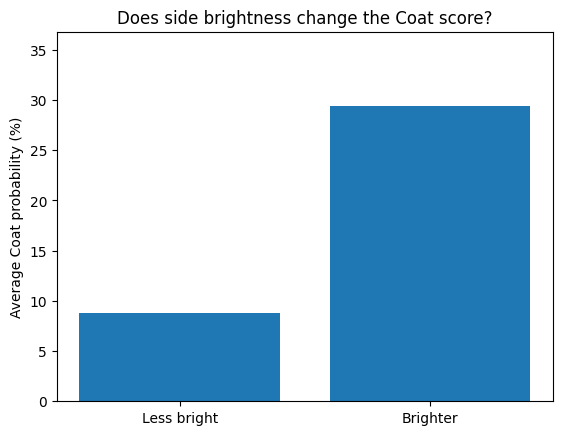

In [11]:
coat_probability = probabilities[shirt_images, coat]

low_prob = 100 * coat_probability[low].mean()
high_prob = 100 * coat_probability[high].mean()

print(f"Less bright sides: average P(Coat) = {low_prob:.1f}%")
print(f"Brighter sides: average P(Coat) = {high_prob:.1f}%")

plt.bar(["Less bright", "Brighter"], [low_prob, high_prob])
plt.ylabel("Average Coat probability (%)")
plt.title("Does side brightness change the Coat score?")
plt.ylim(0, max(low_prob, high_prob, 1) * 1.25)
plt.show()

## 7. Our conclusion

The last cell makes a small summary with the values **from our own run**. Use those numbers when writing your report or explaining your charts.

In [ ]:
print("PHASE 1 SUMMARY")
print(f"1. We found {len(wrong)} shirts that the model called coats.")
print(f"2. The mistake happened for {low_rate:.1f}% of less-bright shirts")
print(f"   and {high_rate:.1f}% of brighter-side shirts.")
print(f"3. On these mistakes, the average Coat probability was {coat_on_mistakes.mean():.1%}.")
print(f"4. On all shirts, average P(Coat) was {low_prob:.1f}% vs {high_prob:.1f}%.") 

if high_rate > low_rate:
    print("Our results support the idea that brighter sides are linked to more Shirt -> Coat errors.")
else:
    print("Our results do not support the idea that brighter sides lead to more Shirt -> Coat errors.")

print("Important: brightness is not the same thing as sleeve length, and this is not proof of cause.")

PHASE 1 SUMMARY
1. We found 177 shirts that the model called coats.
2. The mistake happened for 6.4% of less-bright shirts
   and 29.0% of brighter-side shirts.
3. On these mistakes, the average Coat probability was 66.4%.
4. On all shirts, average P(Coat) was 8.8% vs 29.5%.
Our results support the idea that brighter sides are linked to more Shirt -> Coat errors.
Important: brightness is not the same thing as sleeve length, and this is not proof of cause.
